<a href="https://colab.research.google.com/github/CPTR295/Learning-Langchain/blob/main/SummarizationEngineUsingLangchain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
api_key = userdata.get("OPENROUTER_API_KEY")

In [2]:
!pip install -q langchain langchain_openai langchain_community

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [3]:
!pip install -q bs4

In [4]:
!pip install  -q duckduckgo-search

In [5]:
!pip install -q ddgs

In [6]:
#Websearching.py
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from typing import List

def web_search(web_query: str, num_results: int) -> List[str]:
  return [r["link"] for r in DuckDuckGoSearchAPIWrapper().results(web_query,num_results)]

/tmp/ipykernel_2936/3863063491.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import DuckDuckGoSearchAPIWrapper


In [7]:
#Test above websearch funtion
res = web_search(web_query="How many states does india have?",num_results=5)
print(res)

['https://en.wikipedia.org/wiki/States_and_union_territories_of_India', 'https://en.wikipedia.org/wiki/List_of_state_and_union_territory_capitals_in_India', 'https://www.geeksforgeeks.org/social-science/states-and-capitals-in-india/', 'https://www.indianimmigration.org/faq/how-many-states-are-there-in-india', 'https://anantamias.com/total-state-in-india/']


In [8]:
#Web Scraping
import requests
from bs4 import BeautifulSoup

def web_scrape(url: str) -> str:
  try:
    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
            "AppleWebKit/537.36 (KHTML, like Gecko)"
            "Chrome/110.0.0.0 Safari/537.3"
        ),
        "Accept-Language": "en-US,en;q=0.9",

    }
    response = requests.get(url,headers=headers,timeout=15)
    if response.status_code  == 200:
      soup = BeautifulSoup(response.text,"html.parser")
      page_text = soup.get_text(separator=" ",strip=True)
      return page_text
    else:
      return f"Could not retrieve the webpage: Status code {response.status_code}"
  except Exception as e:
    return f"Could not retrieve the webpage: {str(e)}"

In [9]:
#Test wrbscrpaing
res = web_scrape("https://en.wikipedia.org/wiki/States_and_union_territories_of_India")
print(res)

States and union territories of India - Wikipedia Jump to content Main menu Main menu move to sidebar hide Navigation Main page Contents Current events Random article About Wikipedia Contact us Contribute Help Learn to edit Community portal Recent changes Upload file Special pages Search Search Appearance Donate Create account Log in Personal tools Donate Create account Log in Contents move to sidebar hide (Top) 1 History Toggle History subsection 1.1 1876–1919 1.2 1919–1935 1.3 1935–1947 1.4 1947–1950 1.5 States reorganisation (1951–1956) 1.6 Post-1956 1.7 Current proposals 2 States and union territories Toggle States and union territories subsection 2.1 States 2.2 Union territories 3 Former states and union territories Toggle Former states and union territories subsection 3.1 Former states 3.2 Former union territories 4 Responsibilities and authorities 5 See also 6 References 7 External links Toggle the table of contents States and union territories of India 101 languages Afrikaans A

In [10]:
from langchain_openai import ChatOpenAI
def get_llm():
  return ChatOpenAI( #Many providers provide same api interface as openai including openrouter
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
)

In [11]:
#Utility function
import json
def to_obj(s):
  try:
    return json.loads(s)
  except Exception:
    return {}

In [12]:
#Prompts.py to generate prompts tailored to the query
from langchain_core.prompts import PromptTemplate

ASSISTANT_SELECTION_INSTRUCTION = """
You are a skilled at assigning a research question to the correct research assistant.
There are various research assistants avialble, each specialized in an area of expertise.
Each assistant is identified by a specific type. Each assistant has spedific instructions to undertake the research.

How to select the correct assitant: you must select the relevant assistant depending on the topic of the question, which should match the area of expertise of the assistant.

------
Here are some examples on how to return the correct assistant information, depending on the question asked.

Examples:
Question: "Should I invest in Apple stocks?"
Response:
{{
    "assistant_type": "Financial analyst assistant",
    "assistant_instructions": "You are a seasoned finance analyst AI assistant. Your primary goal is to compose comprehensive, astute, impartial, and methodically arranged financial reports based on provided data and trends.",
    "user_question": {user_question}
}}
Question: "what are the most interesting sites in Tel Aviv?"
Response:
{{
    "assistant_type": "Tour guide assistant",
    "assistant_instructions": "You are a world-travelled AI tour guide assistant. Your main purpose is to draft engaging, insightful, unbiased, and well-structured travel reports on given locations, including history, attractions, and cultural insights.",
    "user_question": "{user_question}"
}}

Question: "Is Messi a good soccer player?"
Response:
{{
    "assistant_type": "Sport expert assistant",
    "assistant_instructions": "You are an experienced AI sport assistant. Your main purpose is to draft engaging, insightful, unbiased, and well-structured sport reports on given sport personalities, or sport events, including factual details, statistics and insights.",
    "user_question": "{user_question}"
}}

------

Now that you have understood all the above, select the correct research assistant for the following questions.
Question: {user_question}
Response:
"""
#Above is a example of few shot template
ASSISTANT_SELECTION_PROMPT_TEMPLATE = PromptTemplate.from_template(
    template = ASSISTANT_SELECTION_INSTRUCTION
)

In [13]:
# WEB SEARCH
WEB_SEARCH_INSTRUCTIONS = """
{assistant_instructions}

Write {num_search_queries} web search queries to gather as much information as possible
on the following question: {user_question}. Your objective is to write a report based on the information you find.
You must respond with a list of queries such as query1, query2, query3 in the following format:
[
    {{"search_query": "query1", "user_question": "{user_question}" }},
    {{"search_query": "query2", "user_question": "{user_question}" }},
    {{"search_query": "query3", "user_question": "{user_question}" }}
]
"""

WEB_SEARCH_PROMPT_TEMPLATE = PromptTemplate.from_template(
    template=WEB_SEARCH_INSTRUCTIONS
)

# INDIVIDUAL SEARCH SUMMARY
SUMMARY_INSTRUCTIONS = """
Read the following text:
Text: {search_result_text}

-----------

Using the above text, answer in short the following question.
Question: {search_query}

-----------
If you cannot answer the question above using the text provided above, then just summarize the text.
Include all factual information, numbers, stats etc if available.
"""

SUMMARY_PROMPT_TEMPLATE = PromptTemplate.from_template(
    template=SUMMARY_INSTRUCTIONS
)

# RESEARCH REPORT
# Research Report prompts adapted from https://github.com/assafelovic/gpt-researcher/blob/master/gpt_researcher/master/prompts.py
RESEARCH_REPORT_INSTRUCTIONS = """
You are an AI critical thinker research assistant. Your sole purpose is to write well written, critically acclaimed, objective and structured reports on given text.

Information:
--------
{research_summary}
--------

Using the above information, answer the following question or topic: "{user_question}" in a detailed report -- \
The report should focus on the answer to the question, should be well structured, informative, \
in depth, with facts and numbers if available and a minimum of 1,200 words.

You should strive to write the report as long as you can using all relevant and necessary information provided.
You must write the report with markdown syntax.
You MUST determine your own concrete and valid opinion based on the given information. Do NOT deter to general and meaningless conclusions.
Write all used source urls at the end of the report, and make sure to not add duplicated sources, but only one reference for each.
You must write the report in apa format.
Please do your best, this is very important to my career."""

RESEARCH_REPORT_PROMPT_TEMPLATE = PromptTemplate.from_template(
    template=RESEARCH_REPORT_INSTRUCTIONS
)

In [17]:
NUM_SEARCH_QUERIES = 2
NUM_SEARCH_RESULTS_PER_QUERY = 2
RESULT_TEXT_MAX_CHARACTERS = 2000
question = 'How can I learn Spanish?'

llm = get_llm()

#select research assistant instructions
assistant_selection_prompt = ASSISTANT_SELECTION_PROMPT_TEMPLATE.format(user_question=question)
assistant_instructions = llm.invoke(assistant_selection_prompt)
assistant_instructions_dict = to_obj(assistant_instructions.content)


assistant_instructions_dict

{'assistant_type': 'Language learning assistant',
 'assistant_instructions': 'You are an experienced AI language learning assistant. Your main purpose is to provide effective, personalized, and structured guidance for language acquisition, including learning strategies, resources, practice methods, and progress tracking for Spanish or other languages.',
 'user_question': 'How can I learn Spanish?'}

In [18]:
#generate search queries
web_search_prompt = WEB_SEARCH_PROMPT_TEMPLATE.format(
    assistant_instructions=assistant_instructions_dict["assistant_instructions"],
    user_question=assistant_instructions_dict['user_question'],
    num_search_queries=NUM_SEARCH_QUERIES
)
web_search_queries = llm.invoke(web_search_prompt)
web_search_queries_list = to_obj(web_search_queries.content.replace('\n',''))
web_search_queries_list

[{'search_query': 'best methods and resources to learn Spanish from beginner to fluent 2024 comprehensive guide',
  'user_question': 'How can I learn Spanish?'},
 {'search_query': 'structured Spanish language learning roadmap CEFR levels self-study plan',
  'user_question': 'How can I learn Spanish?'}]

In [24]:
#find all the search results urls : NUM_SEARCH_QUERIES * NUM_SEARCH_RESULTS_PER_QUERY
searches_and_results_urls = [{
    'result_urls': web_search(
        web_query=wq['search_query'],
        num_results=NUM_SEARCH_RESULTS_PER_QUERY
    ),
    'search_query': wq['search_query']
} for wq in web_search_queries_list]
searches_and_results_urls

[{'result_urls': ['https://languagelearnershub.com/blog/best-way-learn-spanish/',
   'https://www.thespanishexperiment.com/review'],
  'search_query': 'best methods and resources to learn Spanish from beginner to fluent 2024 comprehensive guide'},
 {'result_urls': ['https://langmitra.com/blog/spanish-language-proficiency-roadmap',
   'https://vamos-hablamos.com/blog/spanish-learning-roadmap-b2/'],
  'search_query': 'structured Spanish language learning roadmap CEFR levels self-study plan'}]

In [25]:
#flatten the search urls
search_query_and_result_url_list = []
for qr in searches_and_results_urls:
  search_query_and_result_url_list.extend([{
      'search_query': qr['search_query'],
      'result_url': r
  } for r in qr['result_urls']])

search_query_and_result_url_list

[{'search_query': 'best methods and resources to learn Spanish from beginner to fluent 2024 comprehensive guide',
  'result_url': 'https://languagelearnershub.com/blog/best-way-learn-spanish/'},
 {'search_query': 'best methods and resources to learn Spanish from beginner to fluent 2024 comprehensive guide',
  'result_url': 'https://www.thespanishexperiment.com/review'},
 {'search_query': 'structured Spanish language learning roadmap CEFR levels self-study plan',
  'result_url': 'https://langmitra.com/blog/spanish-language-proficiency-roadmap'},
 {'search_query': 'structured Spanish language learning roadmap CEFR levels self-study plan',
  'result_url': 'https://vamos-hablamos.com/blog/spanish-learning-roadmap-b2/'}]

In [26]:
#scrape the result text from each result url
result_text_list =[{
    'result_text': web_scrape(url=re['result_url'])[:RESULT_TEXT_MAX_CHARACTERS],
    'result_url': re['result_url'],
    'search_query': re['search_query']
} for re in search_query_and_result_url_list]
result_text_list[0]

{'result_text': 'The Best Way to Learn Spanish: From Beginner to Fluent | Language Learners Hub LLH Language Learners Hub Products ⌄ LLH Tutor Your personal AI language teacher LLH Speak Practise with real language learners Features See how the LLH learning loop works Learn ⌄ All languages Choose your learning destination English Spanish French Articles Endangered Articles Tools About Start learning ↗ Products LLH Tutor ↗ LLH Speak ↗ Features Explore Learn a language Articles Endangered Articles Tools About LLH Start learning ↗ Learn spanish for free 19 min read Nov 28, 2024 LLH FIELD NOTE The Best Way to Learn Spanish: From Beginner to Fluent Written by Alex Begin reading ↓ In this article Share X LinkedIn Copy link TL;DR: To go from beginner to fluent in Spanish, you need a simple process: build a foundation across listening, reading, writing, and speaking, then grow high-frequency vocabulary, add grammar in a structured way, and practise listening and speaking until it becomes autom

In [27]:
len(result_text_list)

4

In [29]:
#Summarize the results
result_text_summary_list=[]
for rt in result_text_list:
  summary_prompt = SUMMARY_PROMPT_TEMPLATE.format(
      search_result_text=rt['result_text'],
      search_query=rt['search_query']
  )
  text_summary = llm.invoke(summary_prompt)
  result_text_summary_list.append({
      'text_summary': text_summary,
      'result_url': rt['result_url'],
      'search_query': rt['search_query']
  })

result_text_summary_list[1]

{'text_summary': AIMessage(content='**Summary of Provided Text:**\n\nThe text is an introduction to a "Top 7 Best Online Spanish Language Courses - 2024" article. It notes that learning Spanish at home as an adult differs from school learning and that no single "best" way fits everyone. It highlights that many listed courses offer free trials.\n\n**Detailed Coverage (Only Course Fully Described):**\n\n*   **Top Pick - Best Value: Rocket Spanish**\n    *   **Description:** Comprehensive all-in-one course designed to take learners to intermediate level without supplementary products.\n    *   **Structure:** 3 Levels (Beginner to Upper-Intermediate, approx. **C1 CEFR**).\n    *   **Components per Level:**\n        1.  **Interactive Audio Lessons:** Podcast-style dialogues from everyday situations (~20 mins each); pauses for spoken practice.\n        2.  **Language & Culture Lessons:** Written grammar explanations with built-in audio examples (textbook-style).\n    *   **Note:** Text cuts 

In [30]:
#create a text including result summary and url for each result
stringfied_summary_list = [
    f'Source URL: {sr['result_url']}\nSummary: {sr['text_summary']}' for sr in result_text_summary_list
]

In [32]:
#merge all
appended_result_summaries = '\n'.join(stringfied_summary_list)

In [33]:
#compile report from summaries
research_report_prompt = RESEARCH_REPORT_PROMPT_TEMPLATE.format(
    research_summary=appended_result_summaries,
    user_question=question
)
research_report = llm.invoke(research_report_prompt)

In [35]:
research_report.content

'**Report Title:** Strategic Pathways to Spanish Proficiency: A Critical Synthesis of Contemporary Learning Frameworks, Methodologies, and Resource Ecosystems\n\n**Author:** AI Critical Thinker Research Assistant\n**Date:** October 26, 2023\n**Institution:** Independent Research Division\n\n---\n\n### Abstract\n\nThis report provides a comprehensive, critical analysis of the current landscape for learning Spanish as a second language, synthesized exclusively from four authoritative online sources. It examines the macro-statistics of the language’s global utility, the standardized proficiency frameworks (CEFR) governing assessment, the quantified time investment required for mastery, and the specific methodological architectures proposed by leading platforms. The analysis contrasts the "all-in-one" comprehensive course model (exemplified by Rocket Spanish) with the modular, phase-based self-study roadmaps (Vamos Hablamos, Langmitra) and the AI-augmented ecosystem approach (Language Lear

# Above Using Langchain Expression Language LCEL

In [36]:
#Assistant Instruction Chain
from langchain_core.output_parsers import StrOutputParser #extract response from content
assistant_instructions_chain = ASSISTANT_SELECTION_PROMPT_TEMPLATE | get_llm()

In [37]:
question = 'What is nether?'
assistant_instructions = assistant_instructions_chain.invoke(question)
assistant_instructions

AIMessage(content='{\n    "assistant_type": "General knowledge assistant",\n    "assistant_instructions": "You are a knowledgeable AI reference assistant. Your primary goal is to provide accurate, clear, and well-structured explanations for general knowledge questions, definitions, and factual inquiries across various domains.",\n    "user_question": "What is nether?"\n}', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 591, 'prompt_tokens': 423, 'total_tokens': 1014, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 521, 'rejected_prediction_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia

In [38]:
from langchain_core.runnables import RunnablePassthrough #binds the ext input to the user_question through unnammed parameter
assistant_instructions_chain = (
    {'user_question': RunnablePassthrough()}
    | ASSISTANT_SELECTION_PROMPT_TEMPLATE
    | get_llm()
    | StrOutputParser()
    | to_obj
)


In [39]:
question = 'Expalin Gravity?'

In [40]:
assistant_instructions_dict = assistant_instructions_chain.invoke(question)
assistant_instructions_dict

{'assistant_type': 'Physics expert assistant',
 'assistant_instructions': 'You are a knowledgeable AI physics assistant. Your main purpose is to draft engaging, insightful, unbiased, and well-structured scientific explanations on given physics concepts, including fundamental principles, mathematical formulations, historical context, and real-world applications.',
 'user_question': 'Explain Gravity?'}

In [41]:
from langchain_core.runnables import RunnableLambda
web_search_chain = (
    RunnableLambda( lambda x:
                   {
                       'assistant_instructions': x['assistant_instructions'],
                       'num_search_queries': NUM_SEARCH_QUERIES,
                       'user_question': x['user_question']
                   }
                   )
    | WEB_SEARCH_PROMPT_TEMPLATE
    | get_llm()
    | StrOutputParser()
    | to_obj
)

In [42]:
web_search_list = web_search_chain.invoke(assistant_instructions_dict)
web_search_list

[{'search_query': 'fundamental principles of gravity Newton general relativity quantum gravity theoretical physics overview',
  'user_question': 'Explain Gravity?'},
 {'search_query': 'experimental tests of gravity gravitational waves LIGO black hole imaging Event Horizon Telescope practical applications GPS',
  'user_question': 'Explain Gravity?'}]

In [43]:
search_result_urls_chain = (
    RunnableLambda(lambda x:
                   [
                       {
                           'result_url': url,
                           'search_query': x['search_query'],
                           'user_question': x['user_question']
                       } for url in web_search(
                           web_query=x['search_query'],
                           num_results=NUM_SEARCH_RESULTS_PER_QUERY
                       )

                   ])
)

In [50]:
web_search_str = '{"search_query": "fundamental principles of gravity Newton general relativity quantum gravity theoretical physics overview", "user_question": "Explain Gravity?"}'
web_search_dict = to_obj(web_search_str)
result_urls_list = search_result_urls_chain.invoke(web_search_dict)
print(result_urls_list)

[{'result_url': 'https://en.wikipedia.org/wiki/Quantum_gravity', 'search_query': 'fundamental principles of gravity Newton general relativity quantum gravity theoretical physics overview', 'user_question': 'Explain Gravity?'}, {'result_url': 'https://physics.mit.edu/research-areas/quantum-gravity-and-field-theory/', 'search_query': 'fundamental principles of gravity Newton general relativity quantum gravity theoretical physics overview', 'user_question': 'Explain Gravity?'}]


In [54]:
from langchain_core.runnables import RunnableParallel
search_result_text_and_summary_chain = (
    RunnableLambda( lambda x:
                   {
                       'search_result_text': web_scrape(url=x['result_url'])[:RESULT_TEXT_MAX_CHARACTERS],
                       'result_url': x['result_url'],
                       'search_query': x['search_query'],
                       'user_question': x['user_question']
                   }
    )
    | RunnableParallel(
        {
            'text_summary': SUMMARY_PROMPT_TEMPLATE | get_llm() | StrOutputParser(),
            'result_url': lambda x: x['result_url'],
            'user_question': lambda x: x['user_question']
        }
    )
    | RunnableLambda(lambda x:
        {
            'summary':
               f"Source Url: {x['result_url']}\nSummary: {x['text_summary']}",
            'user_question': x['user_question']
        }
    )
)

In [55]:
result_url_str = '{"result_url": "https://en.wikipedia.org/wiki/Quantum_gravity", "search_query": "fundamental principles of gravity Newton general relativity quantum gravity theoretical physics overview", "user_question": "Explain Gravity?"}'
result_url_dict = to_obj(result_url_str)

search_text_summary = search_result_text_and_summary_chain.invoke(result_url_dict)
print(search_text_summary)

{'summary': 'Source Url: https://en.wikipedia.org/wiki/Quantum_gravity\nSummary: The provided text is only the Wikipedia page structure and navigation for "Quantum gravity" - it contains the table of contents, language links, and site navigation elements, but **no actual article content** about the fundamental principles of gravity, Newton, general relativity, or quantum gravity theories.\n\n**What the text does contain:**\n- Table of contents with sections: Overview, Quantum mechanics and general relativity (with subsections on Graviton, Nonrenormalizability, Effective field theory, Spacetime background dependence, Semi-classical quantum gravity, Problem of time), Candidate theories (String theory, Loop quantum gravity, Other proposals), Experimental tests, See also, Notes, References, Sources, Further reading, External links\n- Navigation elements: Main menu, search, donation links, account tools\n- Language options: 52 languages listed including Afrikaans, Arabic, Bengali, Catalan, 

In [56]:
search_and_summarization_chain = (
    search_result_urls_chain
    | search_result_text_and_summary_chain.map() #To parallelize for each url
    | RunnableLambda(lambda x:
                     {
                         'summary': '\n'.join([i['summary'] for i in x]),
                         'user_question':x[0]['user_question'] if len(x) > 0 else ''
                     })
)

In [57]:
web_research_chain = (
    assistant_instructions_chain
    | web_search_chain
    | search_and_summarization_chain.map()
    | RunnableLambda(lambda x:
                     {
                         'research_summary': '\n\n'.join([i['summary'] for i in x]),
                         'user_question':x[0]['user_question'] if len(x) > 0 else ''
                     })
    | RESEARCH_REPORT_PROMPT_TEMPLATE
    | get_llm()
    | StrOutputParser()
)

In [59]:
res = web_research_chain.invoke(question)
print(res)

# A Structural and Pedagogical Analysis of Gravity Documentation Across Major Knowledge Repositories

**Abstract**

This report provides a critical analysis of the organizational frameworks employed by three prominent knowledge repositories—Wikipedia (Standard English), Simple English Wikipedia, and OpenStax Physics—to document the fundamental physical interaction known as gravity. Based exclusively on the provided source extracts, which consist solely of structural metadata (tables of contents, navigation elements, learning objectives, and language indices) rather than explanatory prose, this analysis reconstructs the epistemological architecture of gravity as presented to distinct audiences. The report identifies a consensus tripartite structure spanning historical development, classical and relativistic theoretical models, and astrophysical applications, while highlighting pedagogical divergences regarding computational emphasis and accessibility. The pervasive presence of extractio

In [68]:
graph = web_research_chain.get_graph()

In [65]:
!pip install grandalf

In [70]:
print(graph.draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	Parallel\3cuser_question\3eInput([Parallel<user_question>Input]):::first
	Passthrough(Passthrough)
	PromptTemplate_1(PromptTemplate)
	ChatOpenAI_1(ChatOpenAI)
	StrOutputParser_1(StrOutputParser)
	to_obj_1(to_obj)
	Lambda_1(Lambda)
	PromptTemplate_2(PromptTemplate)
	ChatOpenAI_2(ChatOpenAI)
	StrOutputParser_2(StrOutputParser)
	to_obj_2(to_obj)
	Lambda_2(Lambda)
	Lambda_3(Lambda)
	Parallel\3ctext_summary\2cresult_url\2cuser_question\3eInput(Parallel<text_summary,result_url,user_question>Input)
	Parallel\3ctext_summary\2cresult_url\2cuser_question\3eOutput(Parallel<text_summary,result_url,user_question>Output)
	PromptTemplate_3(PromptTemplate)
	ChatOpenAI_3(ChatOpenAI)
	StrOutputParser_3(StrOutputParser)
	Lambda_4(Lambda)
	Lambda_5(Lambda)
	Lambda_6(Lambda)
	Lambda_7(Lambda)
	Lambda_8(Lambda)
	PromptTemplate_4(PromptTemplate)
	ChatOpenAI_4(ChatOpenAI)
	StrOutputParser_4(StrOutputParser)
	StrOutputParserOutput([StrOutputParserOutput

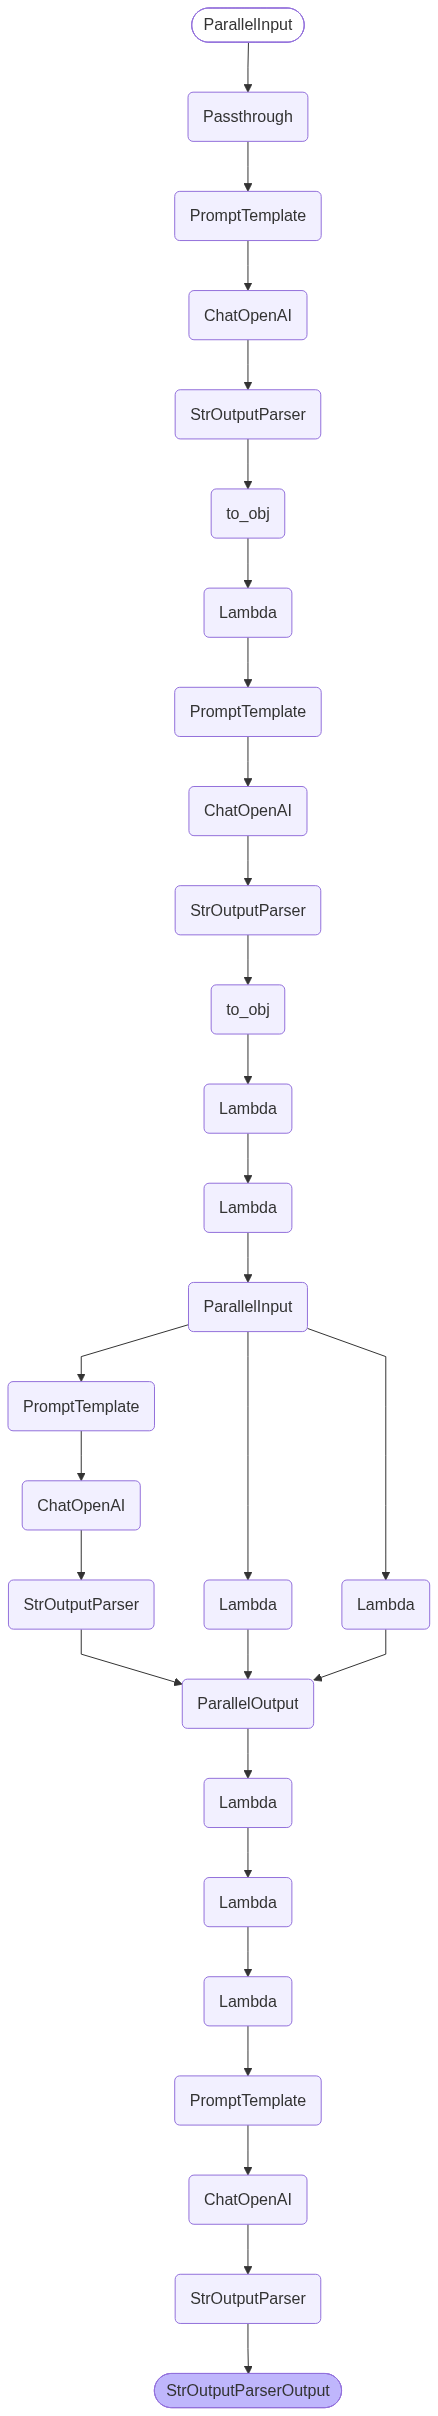

In [72]:
from IPython.display import display, Image
png_data = graph.draw_mermaid_png()

display(Image(png_data))